# UTS Machine Learning – Clustering Segmentasi Pelanggan

**Peran:** Anggota 2 (bagian Clustering) &nbsp;|&nbsp; **Platform:** Python di Google Colab &nbsp;|&nbsp; **Metode:** K-Means (baseline)

**Tujuan:** mengelompokkan 120.000 pelanggan ke dalam segmen berdasarkan kemiripan perilaku belanja. Dataset **tidak memiliki label target**, sehingga ini adalah *unsupervised learning*.

**Alur notebook (sesuai ketentuan tugas):**

| Bagian | Isi | Keluaran wajib yang dihasilkan |
|---|---|---|
| 0 | Persiapan & load data | – |
| 1 | Pemahaman data & kualitas data | – |
| 2 | EDA (distribusi, outlier, korelasi, kolom anonim) | – |
| 3 | Pemilihan fitur | – |
| 4 | Preprocessing (imputasi median + StandardScaler) | – |
| 5 | Pemodelan K=2–10, Elbow, Silhouette | Grafik Elbow, grafik Silhouette |
| 6 | Penentuan K, model final, label cluster | Model terlatih, jumlah pelanggan per cluster |
| 7 | Profil & interpretasi cluster | Tabel profil, interpretasi |
| 8 | Ekspor `cluster.csv` | File `cluster.csv` |
| 9 | Ringkasan & keterbatasan | – |

**Catatan membaca notebook:** setiap cell punya penjelasan **Tujuan** (sebelum kode) dan **Hasil & interpretasi** (setelah output). Tanda ⏳ berarti cell tersebut baru/berubah sehingga outputnya belum ada: jalankan, lalu cocokkan dengan petunjuk yang tertulis.

## 0. Persiapan

**Tujuan:** mengunggah `data_uts_ml.zip`, mengimpor semua library di satu tempat, dan membaca **hanya** dataset clustering (`clustering.csv.gz`). File regresi dan klasifikasi bukan bagian tugas ini.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_uts_ml.zip to data_uts_ml.zip


In [ ]:
# Semua import dikumpulkan di sini agar tidak berulang di cell lain
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")

# Mencari file zip yang diunggah, lalu membaca dataset clustering saja
zip_name = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as z:
    clustering = pd.read_csv(
        z.open("clustering.csv.gz"),
        compression="gzip"
    )

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


**Hasil & interpretasi:** file zip berhasil diunggah dan dataset clustering terbaca. Perbaikan dari versi lama: `import zipfile` sebelumnya tidak ada (kode hanya jalan jika cell lain sudah dijalankan lebih dulu), dan seluruh `import` kini ada dalam satu cell.

## 1. Pemahaman Data & Kualitas Data

### 1.1 Struktur dataset

**Tujuan:** melihat dimensi, tipe data, nama kolom, dan contoh baris.

In [ ]:
# Melihat tipe data setiap kolom
print(clustering.info())

# Melihat seluruh nama kolom
print("\nDaftar kolom:")
print(clustering.columns.tolist())

# Melihat sampel data
display(clustering.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 60 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id_pelanggan            120000 non-null  object 
 1   recency_hari            120000 non-null  float64
 2   frekuensi_90h           120000 non-null  int64  
 3   belanja_90h             120000 non-null  float64
 4   rata2_keranjang         113264 non-null  float64
 5   item_per_pesanan        120000 non-null  int64  
 6   porsi_fashion           120000 non-null  float64
 7   porsi_elektronik        120000 non-null  float64
 8   porsi_kecantikan        120000 non-null  float64
 9   porsi_rumah_tangga      120000 non-null  float64
 10  porsi_makanan_minuman   120000 non-null  float64
 11  porsi_ibu_bayi          120000 non-null  float64
 12  porsi_olahraga          120000 non-null  float64
 13  porsi_hobi              120000 non-null  float64
 14  porsi_otomotif      

,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,...,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,...,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,...,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,...,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,...,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,...,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364


**Hasil & interpretasi:**
- Dataset berisi **120.000 baris dan 60 kolom**.
- Hanya **2 kolom bertipe object**: `id_pelanggan` (identifier) dan `perangkat` (kategorikal). Sisanya numerik.
- Hanya `rata2_keranjang` yang punya nilai kosong (113.264 terisi dari 120.000).
- Ada kolom `n01`–`n15` yang namanya anonim, dibahas di bagian 2.5.

### 1.2 Missing value

**Tujuan:** memastikan kolom mana yang kosong dan seberapa besar, serta melihat sebaran kolom tersebut untuk memilih strategi imputasi.

In [ ]:
# Memeriksa missing value pada clustering
missing = clustering.isnull().sum()

missing = missing[missing > 0]

hasil_missing = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": (
        missing / len(clustering) * 100
    ).round(2)
})

display(hasil_missing)

# Memeriksa statistik fitur yang memiliki missing value
display(
    clustering["rata2_keranjang"].describe()
)

,Jumlah Missing,Persentase (%)
rata2_keranjang,6736,5.61


,rata2_keranjang
count,1.132640e+05
mean,2.803843e+05
std,3.007966e+05
min,9.800000e+03
25%,1.088000e+05
50%,1.839000e+05
75%,3.305000e+05
max,6.457500e+06


**Hasil & interpretasi:**
- Missing value hanya pada `rata2_keranjang`: **6.736 data (5,61%)**.
- Sebaran `rata2_keranjang` miring ke kanan (rata-rata ≈ 280.384 jauh di atas median ≈ 183.900; maksimum ≈ 6,46 juta). Karena itu **median** lebih tepat daripada rata-rata untuk mengisi nilai kosong, sebab median tidak ikut tertarik nilai ekstrem.

**Tujuan (lanjutan):** *mengapa* `rata2_keranjang` kosong? Jika kosong karena pelanggan memang belum bertransaksi, itu bukan kekosongan acak, dan imputasi median harus dibaca dengan hati-hati.

In [ ]:
# Apakah nilai kosong berkaitan dengan pelanggan tanpa transaksi?
kosong = clustering["rata2_keranjang"].isnull().rename("rata2_keranjang kosong")

display(pd.crosstab(kosong, (clustering["frekuensi_90h"] == 0).rename("frekuensi_90h = 0"), margins=True))
display(pd.crosstab(kosong, (clustering["belanja_90h"] == 0).rename("belanja_90h = 0"), margins=True))

**Hasil & interpretasi:** ⏳ jalankan cell di atas, lalu baca tabelnya.
- Jika hampir semua baris "kosong = True" berada di kolom "frekuensi_90h = 0" / "belanja_90h = 0", berarti kosong karena **belum ada transaksi** (bukan data hilang acak). Tulis ini di laporan sebagai keterbatasan: pelanggan tersebut mendapat nilai median keranjang yang sebenarnya tidak mereka miliki.
- Jika sebarannya tidak terkait, imputasi median tetap wajar dan tidak perlu catatan tambahan.

### 1.3 Duplikasi dan identifier

**Tujuan:** memastikan tidak ada baris ganda dan `id_pelanggan` benar-benar unik, agar satu pelanggan tidak dihitung dua kali.

In [ ]:
jumlah_duplikat = clustering.duplicated().sum()
print(f"Baris duplikat: {jumlah_duplikat:,}")

Baris duplikat: 0


In [ ]:
# Identifier harus unik dan tidak kosong
print(f"Jumlah baris             : {len(clustering):,}")
print(f"Jumlah id_pelanggan unik : {clustering['id_pelanggan'].nunique():,}")
print(f"id_pelanggan kosong      : {clustering['id_pelanggan'].isnull().sum():,}")

**Hasil & interpretasi:**
- Baris duplikat: **0**, jadi tidak ada penghapusan yang diperlukan.
- ⏳ Cell kedua: nilai "id unik" harus **sama dengan jumlah baris (120.000)** dan "id kosong" harus 0. Jika sama, `id_pelanggan` valid sebagai kunci untuk `cluster.csv`. `id_pelanggan` **tidak dipakai sebagai fitur**.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Statistik deskriptif dan distribusi fitur kandidat

**Tujuan:** melihat ringkasan statistik seluruh kolom numerik dan bentuk distribusi lima fitur kandidat. Daftar lima fitur ini (`fitur_model`) didefinisikan **sekali** di sini dan dipakai ulang di cell-cell berikutnya.

,count,mean,std,min,25%,50%,75%,max
recency_hari,120000.0,2.454335e+01,4.900982e+01,0.200,5.40000,1.010000e+01,2.180000e+01,2.039800e+03
frekuensi_90h,120000.0,9.705408e+00,1.092228e+01,0.000,3.00000,7.000000e+00,1.300000e+01,2.040000e+02
belanja_90h,120000.0,2.936216e+06,5.716273e+06,0.000,410300.00000,1.136500e+06,3.060225e+06,2.618368e+08
rata2_keranjang,113264.0,2.803843e+05,3.007966e+05,9800.000,108800.00000,1.839000e+05,3.305000e+05,6.457500e+06
item_per_pesanan,120000.0,3.041992e+00,2.577117e+00,1.000,1.00000,2.000000e+00,4.000000e+00,5.100000e+01
porsi_fashion,120000.0,1.410845e-01,1.363748e-01,0.000,0.04010,9.990000e-02,1.999000e-01,9.695000e-01
porsi_elektronik,120000.0,6.395457e-02,8.159090e-02,0.000,0.00910,3.530000e-02,8.710000e-02,9.134000e-01
porsi_kecantikan,120000.0,9.071378e-02,9.945362e-02,0.000,0.02010,5.860000e-02,1.263000e-01,9.366000e-01
porsi_rumah_tangga,120000.0,9.122383e-02,9.832835e-02,0.000,0.02080,6.000000e-02,1.287000e-01,9.044000e-01
porsi_makanan_minuman,120000.0,1.484504e-01,1.398378e-01,0.000,0.04420,1.068000e-01,2.105000e-01,9.866000e-01


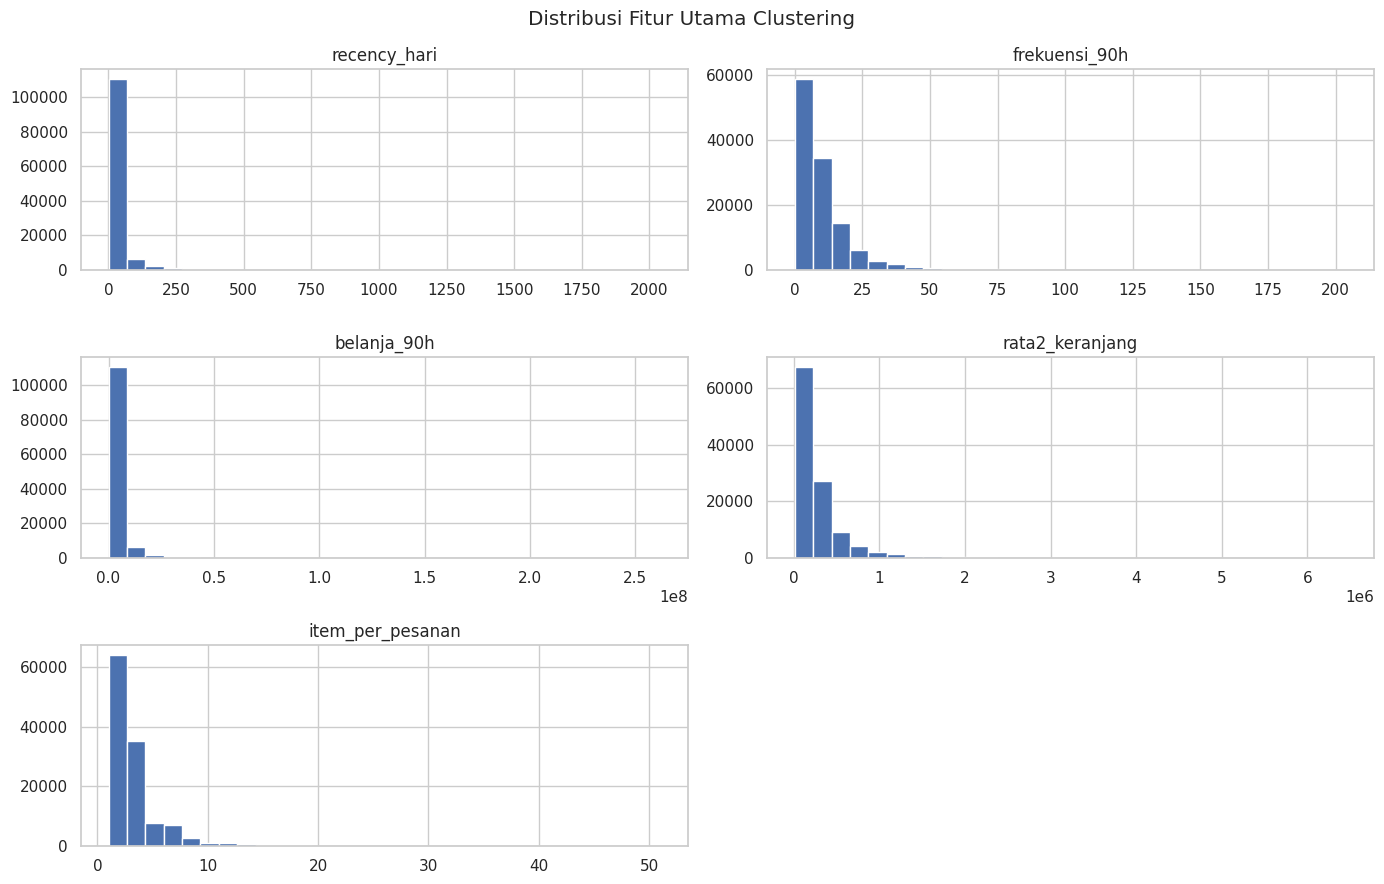

In [ ]:
# Statistik deskriptif fitur numerik
display(clustering.describe().T)

# Lima fitur kandidat untuk baseline clustering (dipakai ulang di cell berikutnya)
fitur_model = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan"
]

clustering[fitur_model].hist(
    figsize=(14, 9),
    bins=30
)

plt.suptitle("Distribusi Fitur Utama Clustering")
plt.tight_layout()
plt.show()

**Hasil & interpretasi:**
- Kelima fitur **sangat miring ke kanan** (ekor panjang): mayoritas pelanggan bernilai kecil, segelintir sangat besar.
  - `recency_hari`: median ≈ 10 hari, maksimum ≈ 2.040 hari.
  - `frekuensi_90h`: median 7, maksimum 204.
  - `belanja_90h`: median ≈ 1,14 juta, maksimum ≈ 261,8 juta.
  - `rata2_keranjang`: median ≈ 183.900, maksimum ≈ 6,46 juta.
  - `item_per_pesanan`: median 2, maksimum 51.
- Implikasi: skala antarfitur sangat berbeda (hari vs rupiah), sehingga **standardisasi wajib**; kemiringan juga berarti **K-Means rawan didominasi pelanggan ekstrem** (lihat 4.2).

### 2.2 Outlier (metode IQR)

**Tujuan:** mengukur proporsi outlier di setiap kolom numerik. Outlier **tidak dihapus** otomatis karena dapat merepresentasikan pelanggan yang memang berbeda (misalnya pelanggan bernilai sangat tinggi).

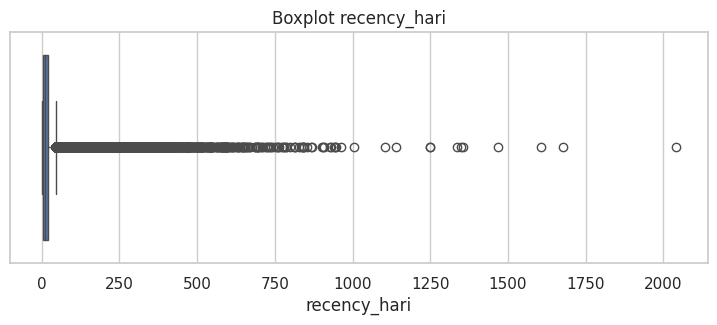

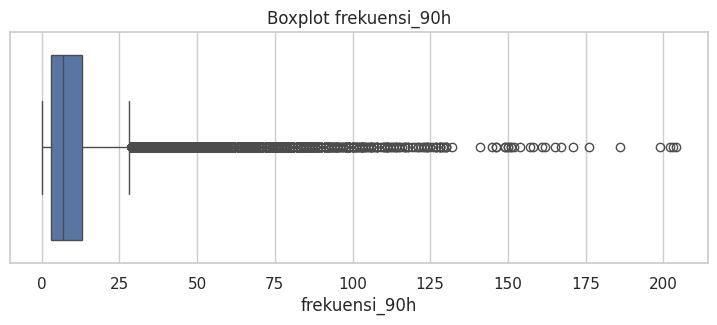

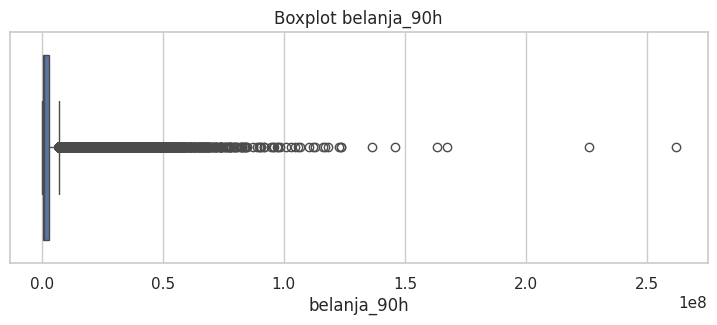

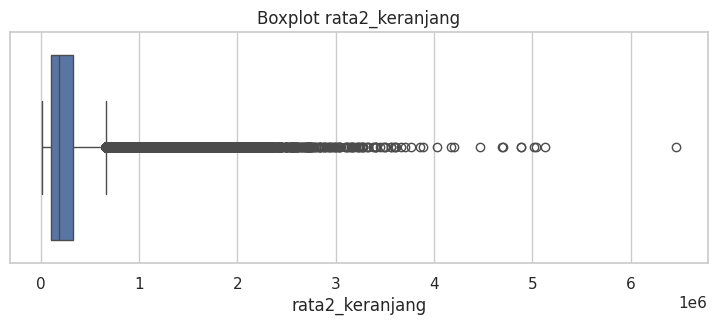

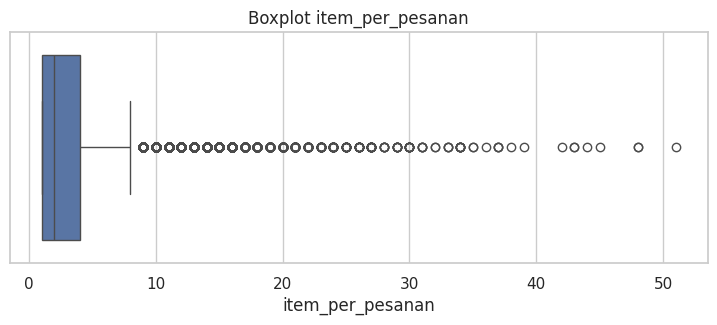

In [ ]:
# Boxplot lima fitur kandidat
for fitur in fitur_model:

    plt.figure(figsize=(9, 3))

    sns.boxplot(
        x=clustering[fitur]
    )

    plt.title(f"Boxplot {fitur}")
    plt.xlabel(fitur)
    plt.show()

In [ ]:
# Memilih fitur numerik
fitur_numerik = clustering.select_dtypes(
    include=np.number
)

# Menghitung outlier menggunakan metode IQR
hasil_outlier = []

for kolom in fitur_numerik.columns:
    Q1 = fitur_numerik[kolom].quantile(0.25)
    Q3 = fitur_numerik[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah = (
        (fitur_numerik[kolom] < batas_bawah) |
        (fitur_numerik[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "Fitur": kolom,
        "Jumlah Outlier": jumlah,
        "Persentase (%)": round(
            jumlah / len(clustering) * 100, 2
        )
    })

outlier_df = pd.DataFrame(hasil_outlier)

display(
    outlier_df.sort_values(
        "Persentase (%)",
        ascending=False
    ).head(20)
)

,Fitur,Jumlah Outlier,Persentase (%)
46,n04,18733,15.61
53,n11,18576,15.48
0,recency_hari,14649,12.21
41,belanja_30h,12653,10.54
54,n12,12631,10.53
47,n05,12633,10.53
44,n02,12481,10.40
2,belanja_90h,12440,10.37
51,n09,12378,10.32
19,porsi_pertanian,11148,9.29


**Hasil & interpretasi:**
- Boxplot: titik-titik di sisi kanan batas whisker sangat banyak pada `recency_hari`, `belanja_90h`, dan `rata2_keranjang`, konsisten dengan distribusi miring ke kanan.
- Tabel IQR (20 teratas): `recency_hari` **12,21%**, `belanja_90h` **10,37%**, `rata2_keranjang` **7,78%** terdeteksi outlier. `frekuensi_90h` dan `item_per_pesanan` tidak masuk 20 teratas.
- Proporsi sebesar 10% lebih menunjukkan aturan IQR sedang menandai **ekor panjang yang wajar**, bukan kesalahan input. **Keputusan: outlier dipertahankan**, dan dampaknya terhadap hasil diuji lewat perbandingan transformasi log di bagian 6.5.

### 2.3 Korelasi antarfitur

**Tujuan:** mencari fitur yang berkorelasi sangat tinggi (redundan). Korelasi dihitung **sekali**, lalu dipakai untuk heatmap dan daftar pasangan teratas.

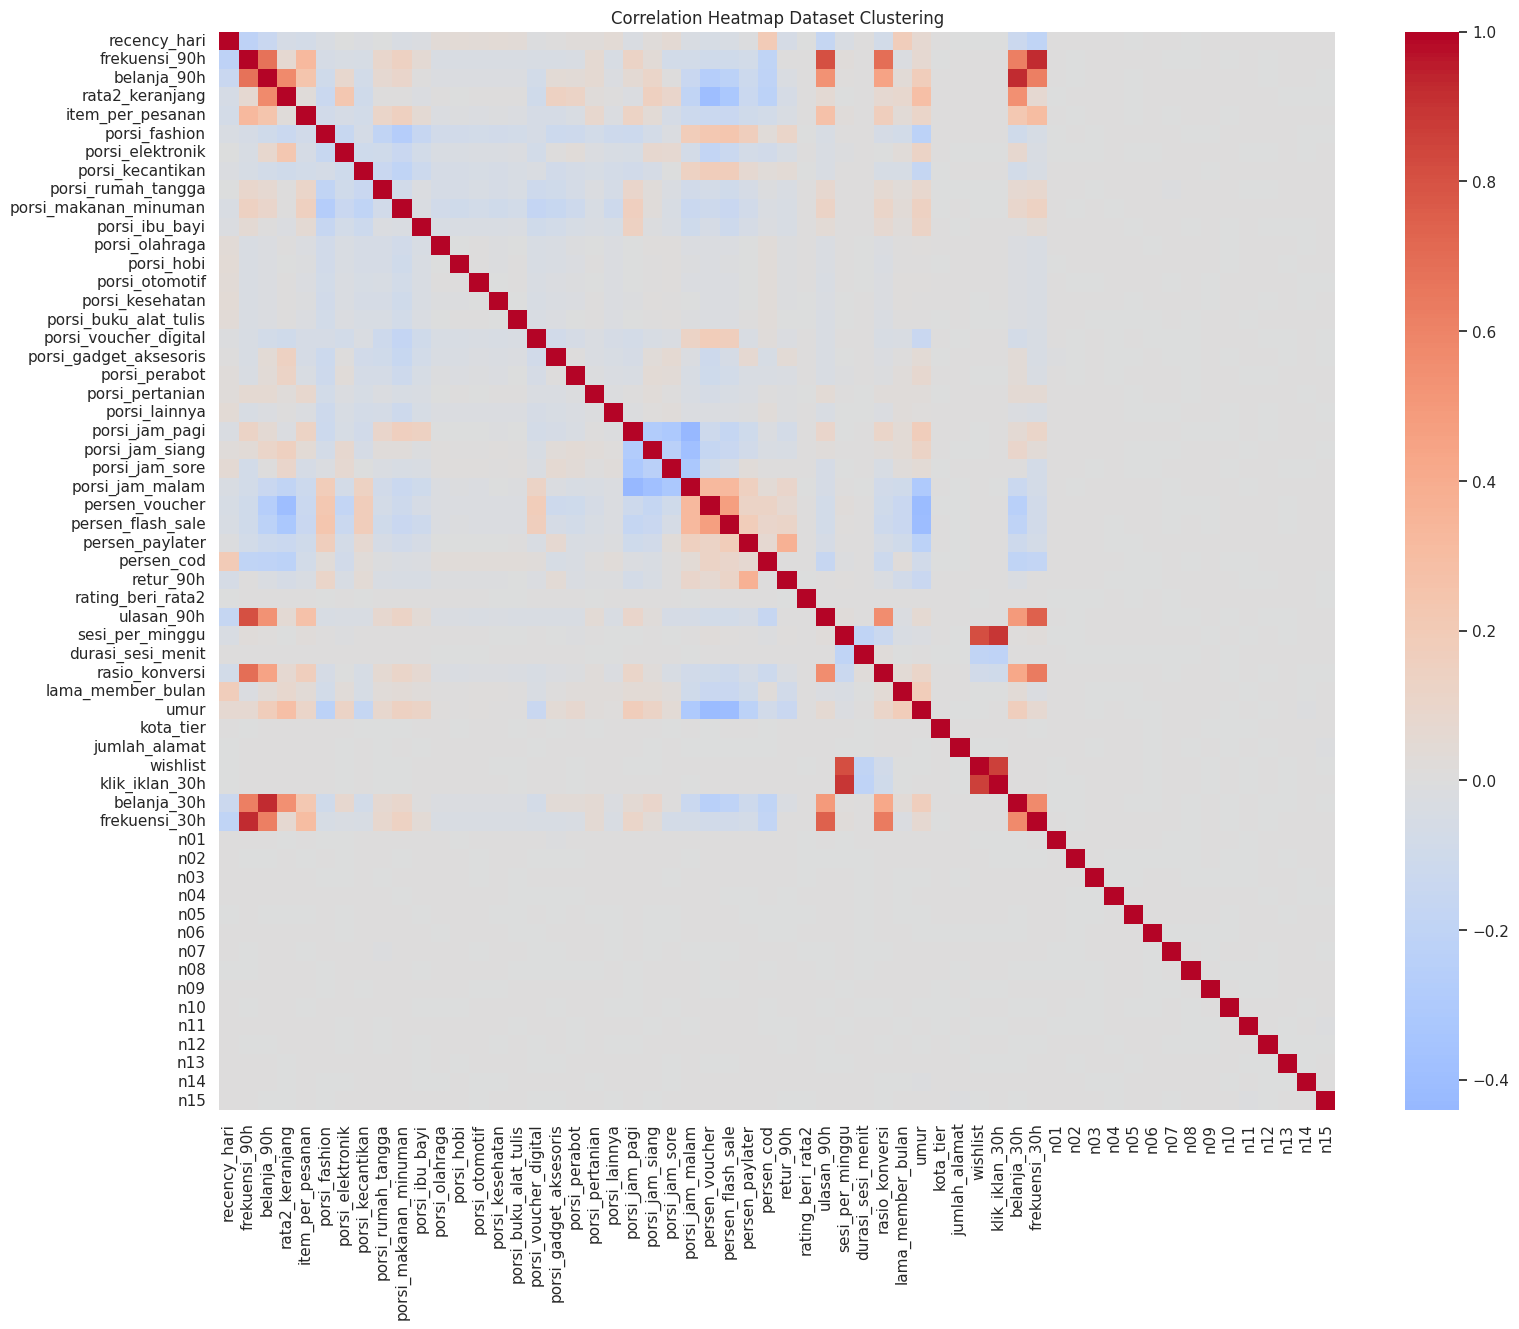

,Fitur 1,Fitur 2,Korelasi,Korelasi Absolut
151,belanja_90h,belanja_30h,0.926339,0.926339
97,frekuensi_90h,frekuensi_30h,0.926311,0.926311
1335,sesi_per_minggu,klik_iklan_30h,0.889104,0.889104
1482,wishlist,klik_iklan_30h,0.861659,0.861659
1334,sesi_per_minggu,wishlist,0.810938,0.810938
86,frekuensi_90h,ulasan_90h,0.805805,0.805805
1312,ulasan_90h,frekuensi_30h,0.746180,0.746180
89,frekuensi_90h,rasio_konversi,0.691939,0.691939
57,frekuensi_90h,belanja_90h,0.669006,0.669006
1384,rasio_konversi,frekuensi_30h,0.639818,0.639818


In [ ]:
# Korelasi antarfitur numerik (dihitung sekali)
corr = clustering.corr(numeric_only=True)

# (a) Heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap Dataset Clustering")
plt.show()

# (b) 20 pasangan fitur dengan korelasi absolut tertinggi
# (segitiga atas saja agar pasangan tidak berulang)
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pasangan_korelasi = (
    upper.stack()
    .reset_index()
)

pasangan_korelasi.columns = [
    "Fitur 1",
    "Fitur 2",
    "Korelasi"
]

pasangan_korelasi["Korelasi Absolut"] = (
    pasangan_korelasi["Korelasi"].abs()
)

display(
    pasangan_korelasi.sort_values(
        "Korelasi Absolut",
        ascending=False
    ).head(20)
)

**Hasil & interpretasi:**
- Pasangan paling redundan: `belanja_90h`–`belanja_30h` (**0,926**) dan `frekuensi_90h`–`frekuensi_30h` (**0,926**). Versi 30 hari hampir mengulang informasi versi 90 hari, jadi cukup satu jendela waktu (90 hari) agar perilaku yang sama tidak terhitung dua kali di jarak K-Means.
- Korelasi tinggi lain berada di kelompok aktivitas aplikasi: `sesi_per_minggu`–`klik_iklan_30h` (0,889), `wishlist`–`klik_iklan_30h` (0,862), `sesi_per_minggu`–`wishlist` (0,811), serta `frekuensi_90h`–`ulasan_90h` (0,806).
- **Di antara lima fitur kandidat**, korelasi tertinggi hanya `frekuensi_90h`–`belanja_90h` (**0,669**) dan `belanja_90h`–`rata2_keranjang` (**0,577**). Pasangan kandidat lainnya tidak masuk 20 teratas (di bawah ≈ 0,45). Artinya kelima fitur **tidak redundan berlebihan** dan masing-masing membawa informasi berbeda.

### 2.4 Fitur kategorikal

**Tujuan:** memeriksa sebaran `perangkat`, satu-satunya fitur kategorikal yang bukan identifier.

In [ ]:
print("\nDistribusi perangkat")
display(clustering["perangkat"].value_counts(dropna=False))


Distribusi perangkat


,count
perangkat,
android,77760
ios,31710
web,10530


**Hasil & interpretasi:** android **77.760 (64,8%)**, ios **31.710 (26,4%)**, web **10.530 (8,8%)**, tanpa nilai kosong. `perangkat` tidak dipakai di baseline karena K-Means berbasis jarak Euclidean dan memerlukan encoding khusus untuk data kategorikal. Variabel ini lebih tepat dipakai nanti untuk **menjelaskan profil cluster** (misalnya komposisi perangkat per cluster).

### 2.5 Kolom anonim `n01`–`n15`

**Tujuan:** memeriksa kolom anonim. Kamus data PDF hanya mendeskripsikan `n01`–`n10`, sedangkan CSV memiliki `n01`–`n15`. **Definisi kolom ini tidak diasumsikan.**

In [ ]:
# Mengambil fitur anonim (nama persis n01 ... n15)
fitur_anonim = clustering.columns[clustering.columns.str.match(r"^n\d{2}$")].tolist()

print("Fitur anonim:")
print(fitur_anonim)

# Statistik deskriptif fitur anonim
display(clustering[fitur_anonim].describe().T)

Fitur anonim:
['n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n07', 'n08', 'n09', 'n10', 'n11', 'n12', 'n13', 'n14', 'n15']


,count,mean,std,min,25%,50%,75%,max
n01,120000.0,50.032386,28.873637,0.001,25.00300,50.1145,74.98650,99.999
n02,120000.0,19.586751,47.312240,0.017,2.85475,7.3560,18.81600,2533.811
n03,120000.0,4.012933,1.998345,0.000,3.00000,4.0000,5.00000,15.000
n04,120000.0,-0.065667,25.828654,-500.000,-0.99900,-0.0020,0.99900,500.000
n05,120000.0,19.380616,135.801538,0.000,2.13400,5.8575,15.22225,25629.432
n06,120000.0,0.500163,0.353300,0.000,0.14700,0.5010,0.85400,1.000
n07,120000.0,0.003421,1.001510,-4.509,-0.66900,0.0020,0.68000,4.024
n08,120000.0,49.924266,28.849373,0.002,24.91675,49.8320,74.87375,99.999
n09,120000.0,19.537655,44.861039,0.015,2.85300,7.4220,19.10925,2843.352
n10,120000.0,4.007908,2.003637,0.000,3.00000,4.0000,5.00000,16.000


**Hasil & interpretasi (hanya pengamatan statistik, bukan definisi):**
- Ada 15 kolom (`n01`–`n15`), lebih banyak dari 10 kolom di kamus data PDF. **Selisih 5 kolom ini belum dapat dijelaskan** dari dokumen yang ada.
- Pola sebaran yang terlihat: `n01`, `n08`, `n15` berkisar 0–100 dengan kuartil rata (≈ 25/50/75); `n03`, `n10` tampak seperti bilangan bulat kecil (kuartil 3/4/5); `n04`, `n11` berkisar −500 sampai 500; `n06`, `n13` berkisar 0–1; `n07`, `n14` bermean ≈ 0 dan simpang baku ≈ 1. Kelompok `n08`–`n14` memiliki **bentuk sebaran yang hampir sama** dengan `n01`–`n07`.
- Keputusan: **semua `n01`–`n15` dikeluarkan dari baseline** sampai maknanya terverifikasi lewat kamus data/dosen. Jika ternyata bermakna perilaku pelanggan, kolom tersebut bisa dipertimbangkan pada iterasi berikutnya.

## 3. Pemilihan Fitur

**Tujuan:** menetapkan fitur untuk baseline beserta alasan ilmiahnya. Kelima fitur kandidat mengikuti kerangka **RFM** (*Recency, Frequency, Monetary*) yang lazim untuk segmentasi pelanggan, ditambah dua ukuran pola pembelian.

| Fitur | Peran | Alasan dipilih |
|---|---|---|
| `recency_hari` | Recency | Seberapa baru pelanggan terakhir bertransaksi (aktif atau mulai pasif) |
| `frekuensi_90h` | Frequency | Seberapa sering bertransaksi dalam 90 hari |
| `belanja_90h` | Monetary | Total nilai belanja dalam 90 hari |
| `rata2_keranjang` | Pola belanja | Nilai rata-rata per pesanan, membedakan pembelanja sedikit-tapi-besar dari sering-tapi-kecil |
| `item_per_pesanan` | Pola belanja | Jumlah barang per pesanan (borongan vs eceran) |

**Fitur yang sengaja tidak dipakai di baseline:**

| Fitur | Alasan |
|---|---|
| `id_pelanggan` | Identifier, tidak mengandung perilaku |
| `perangkat` | Kategorikal, perlu encoding; lebih cocok untuk menjelaskan profil |
| `n01`–`n15` | Definisi belum terverifikasi (kamus data tidak cocok dengan CSV) |
| `belanja_30h`, `frekuensi_30h` | Korelasi 0,93 dengan versi 90 hari, redundan |
| `porsi_*`, `persen_*`, dan fitur lain | Mengukur preferensi kategori/metode bayar/aplikasi, bukan intensitas transaksi; bisa menjadi pengembangan lanjutan |

In [ ]:
# Membuat dataset khusus untuk modeling dari fitur_model (didefinisikan di bagian 2.1)
X = clustering[fitur_model].copy()

# Memeriksa hasil pemilihan fitur
display(X.head())

print("Ukuran data:", X.shape)
print("\nMissing value:")
print(X.isnull().sum())

,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan
0,8.8,6,540100.0,90000.0,3
1,14.6,6,6035900.0,1006000.0,3
2,4.1,15,4006600.0,267100.0,1
3,21.9,2,659500.0,329800.0,1
4,7.0,8,4056500.0,507100.0,4


Ukuran data: (120000, 5)

Missing value:
recency_hari           0
frekuensi_90h          0
belanja_90h            0
rata2_keranjang     6736
item_per_pesanan       0
dtype: int64


**Hasil & interpretasi:** matriks fitur berukuran **120.000 × 5**. Satu-satunya fitur dengan nilai kosong adalah `rata2_keranjang` (6.736), sama dengan temuan di bagian 1.2.

## 4. Preprocessing

### 4.1 Kemiringan distribusi (alasan memeriksa skala)

**Tujuan:** mengukur *skewness* lima fitur secara angka. Nilai di atas ≈ 1 menandakan miring kanan yang kuat.

In [ ]:
display(X.skew().round(2).to_frame("Skewness"))

**Hasil & interpretasi:** ⏳ jalankan, lalu baca. Dari histogram bagian 2.1 hampir pasti semua bernilai positif besar. `StandardScaler` hanya menyamakan skala (mean 0, simpang baku 1) dan **tidak memperbaiki kemiringan**; ekor panjang tetap ada sebagai nilai z yang sangat besar. Efeknya dibahas di 6.5.

### 4.2 Imputasi median dan standardisasi

**Tujuan:** mengisi `rata2_keranjang` yang kosong dengan **median**, lalu menstandardisasi semua fitur dengan `StandardScaler`. Standardisasi wajib karena K-Means memakai jarak Euclidean; tanpa itu `belanja_90h` (jutaan rupiah) akan menenggelamkan `recency_hari` (puluhan hari).

In [ ]:
# Mengisi missing value dengan median
imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

# Melakukan standardisasi
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Preprocessing selesai!")
print("Ukuran data setelah preprocessing:", X_scaled.shape)

Preprocessing selesai!
Ukuran data setelah preprocessing: (120000, 5)


**Hasil & interpretasi:** data siap dimodelkan dengan ukuran **120.000 × 5**, tanpa nilai kosong. Karena ini *unsupervised*, imputer dan scaler boleh dilatih pada seluruh data (tidak ada risiko *data leakage* label seperti pada supervised learning).

## 5. Pemodelan K-Means dan Evaluasi Jumlah Cluster

### 5.1 Mencoba K = 2 sampai 10

**Tujuan:** melatih K-Means untuk setiap K, lalu mencatat **inertia** (untuk Elbow), **Silhouette Score**, dan **persentase cluster terkecil** (untuk mendeteksi cluster yang terlalu kecil). Silhouette dihitung pada sampel 5.000 titik (`random_state=42`) agar efisien; ini perkiraan, bukan nilai pada seluruh 120.000 data.

In [ ]:
inertia_values = []
silhouette_values = []
min_share_values = []   # persentase cluster terkecil untuk tiap K

# Mencoba jumlah cluster dari 2 sampai 10
for k in range(2, 11):

    print(f"Memproses K = {k}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Menyimpan inertia
    inertia_values.append(kmeans.inertia_)

    # Menghitung silhouette menggunakan sampel
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_values.append(score)
    min_share_values.append(np.bincount(labels).min() / len(labels) * 100)

print("Selesai!")

Memproses K = 2
Memproses K = 3
Memproses K = 4
Memproses K = 5
Memproses K = 6
Memproses K = 7
Memproses K = 8
Memproses K = 9
Memproses K = 10
Selesai!


**Hasil & interpretasi:** model berhasil dilatih untuk K = 2 sampai 10 (`n_init=10` dan `random_state=42` membuat hasil dapat direproduksi).

### 5.2 Grafik Elbow Method

**Tujuan:** mencari K di mana penurunan inertia (jumlah kuadrat jarak titik ke pusat cluster) mulai melandai.

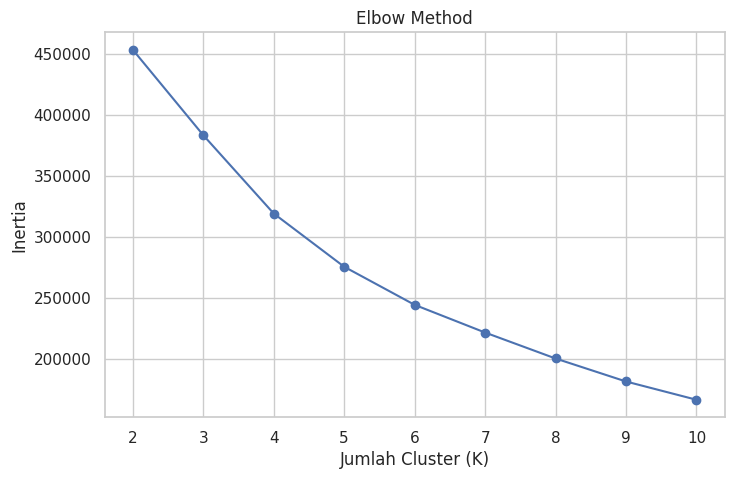

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

**Hasil & interpretasi (nilai dibaca dari grafik, perkiraan):**
- Inertia turun terus dari ≈ 453 ribu (K=2) ke ≈ 384 ribu (K=3), ≈ 319 ribu (K=4), ≈ 275 ribu (K=5), lalu ≈ 167 ribu (K=10).
- Kurva **melengkung mulus tanpa siku yang tegas**. Penurunan sedikit melambat setelah K=4–5, tetapi tidak ada satu titik yang jelas. Inertia **pasti turun saat K naik**, jadi Elbow tidak boleh dipakai sendirian untuk memilih K; ia hanya petunjuk awal.

### 5.3 Grafik Silhouette Score

**Tujuan:** menilai seberapa baik titik cocok dengan clusternya sendiri dibanding cluster lain. Rentang −1 sampai 1; makin tinggi makin baik. Pedoman umum (Kaufman & Rousseeuw): sekitar 0,51–0,70 struktur wajar, 0,26–0,50 struktur lemah, ≤ 0,25 hampir tidak ada struktur.

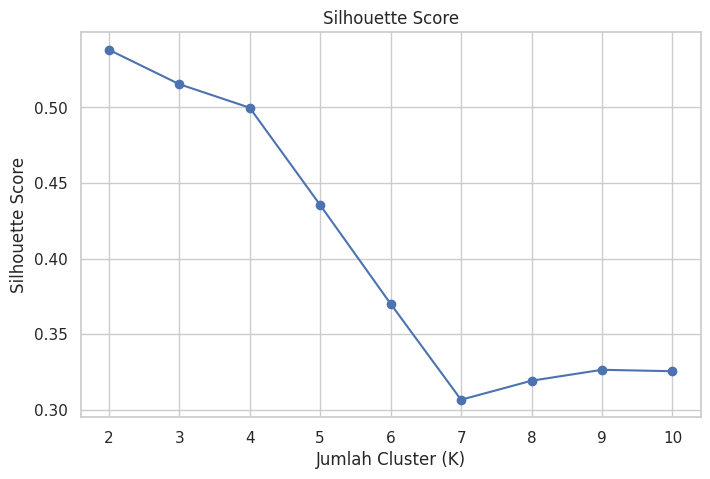

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

**Hasil & interpretasi (perkiraan dari grafik):**
- Tertinggi di **K=2 (≈ 0,54)**, lalu menurun: K=3 ≈ 0,52, **K=4 ≈ 0,50**, K=5 ≈ 0,44, K=6 ≈ 0,37, minimum di K=7 (≈ 0,31), lalu sedikit naik ke ≈ 0,32–0,33 pada K=8–10.
- Ada **penurunan tajam setelah K=4** (0,50 → 0,44 → 0,37). K=2 sampai 4 berada di sekitar batas 0,5 (struktur wajar sampai batas lemah), sedangkan K ≥ 5 jelas lebih lemah.
- Silhouette tertinggi di K=2 belum otomatis berarti K=2 terbaik untuk tujuan **segmentasi**: dua kelompok umumnya terlalu kasar untuk dipakai bisnis. Selain itu, skor tinggi pada data bermiringan kuat bisa muncul karena satu kelompok besar dipisahkan dari sedikit pelanggan ekstrem (lihat 6.5).

### 5.4 Tabel ringkasan evaluasi

**Tujuan:** menggabungkan inertia, silhouette, dan ukuran cluster terkecil dalam satu tabel sebagai dasar keputusan K (dengan angka pasti, bukan perkiraan grafik).

In [ ]:
ringkasan_k = pd.DataFrame({
    "K": range(2, 11),
    "Inertia": np.round(inertia_values, 0),
    "Penurunan inertia (%)": (-pd.Series(inertia_values).pct_change() * 100).round(1),
    "Silhouette (sampel 5.000)": np.round(silhouette_values, 4),
    "Cluster terkecil (%)": np.round(min_share_values, 2),
}).set_index("K")

display(ringkasan_k)

**Hasil & interpretasi:** ⏳ jalankan, lalu cek tiga hal.
1. **Silhouette**: urutkan dari tertinggi; bandingkan K=2, 3, 4 (selisihnya kecil).
2. **Penurunan inertia (%)**: cari K setelah mana penurunannya jelas mengecil.
3. **Cluster terkecil (%)**: cluster di bawah ≈ 1% dari data (≈ 1.200 pelanggan) terlalu kecil untuk dijadikan segmen yang stabil. Pada percobaan awal dengan K=3, ukuran clusternya **101.806 / 13.015 / 5.179 pelanggan (≈ 84,8% / 10,8% / 4,3%)**, yakni sangat timpang karena satu cluster menampung hampir seluruh pelanggan.

## 6. Penentuan K Final dan Model Final

### 6.1 Dasar keputusan

K ditentukan dengan **mempertimbangkan beberapa bukti sekaligus**, bukan satu metrik:

| Bukti | Pengamatan |
|---|---|
| Silhouette | Tertinggi di K=2 (≈ 0,54), lalu K=3 (≈ 0,52) dan K=4 (≈ 0,50), turun tajam setelah K=4 |
| Elbow | Melengkung mulus, melandai sedikit setelah K=4–5, tanpa siku tegas |
| Ukuran cluster | Harus diperiksa pada tabel 5.4 (tidak ada cluster < ≈ 1%) |
| Kebermanfaatan | K=2 terlalu kasar untuk segmentasi; K ≥ 5 kualitas menurun |

**Keputusan sementara: `K_FINAL = 4`**, yaitu K terbesar sebelum silhouette turun tajam sambil tetap memberi segmentasi lebih rinci daripada K=2. **Wajib diverifikasi** dengan tabel 5.4 dan profil di bagian 7:
- jika ada cluster < ≈ 1%, atau profil dua cluster tidak bisa dibedakan secara bisnis, **turunkan ke K=3**;
- ubah hanya angka `K_FINAL` di cell berikutnya, seluruh bagian setelahnya otomatis menyesuaikan.

Pada saat presentasi, jelaskan alasannya sebagai *trade-off* antara kualitas statistik dan kegunaan bisnis.

In [ ]:
# Jumlah cluster final (ubah di sini jika hasil verifikasi menuntut)
K_FINAL = 4

# Melatih model K-Means final pada data yang sudah distandardisasi
kmeans_final = KMeans(
    n_clusters=K_FINAL,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

# Menambahkan label cluster ke setiap pelanggan
hasil_clustering = clustering.copy()
hasil_clustering["cluster"] = cluster_labels

# Jumlah dan persentase pelanggan per cluster
ukuran = hasil_clustering["cluster"].value_counts().sort_index()

display(pd.DataFrame({
    "Jumlah pelanggan": ukuran,
    "Persentase (%)": (ukuran / len(hasil_clustering) * 100).round(2)
}))

skor_final = silhouette_score(
    X_scaled, cluster_labels, sample_size=5000, random_state=42
)
print(f"K final = {K_FINAL} | Silhouette (sampel 5.000) = {skor_final:.4f}")

### 6.2 Hasil model final

**Tujuan:** melatih model final, memberi label cluster ke semua pelanggan, dan memeriksa keseimbangan ukuran.

**Hasil & interpretasi:** ⏳ jalankan, lalu cek.
- Jumlah seluruh pelanggan pada tabel harus **120.000**.
- Cluster terkecil sebaiknya **≥ ≈ 1%**. Jika jauh lebih kecil, lihat 6.1 (turunkan K).
- Cluster yang timpang (satu cluster sangat dominan) wajar pada data bermiringan kuat, tetapi harus dijelaskan: cluster besar biasanya pelanggan "tipikal" dan cluster kecil kelompok ekstrem (pelanggan bernilai sangat tinggi atau sangat pasif).
- Silhouette K final harus sesuai dengan baris yang sama di tabel 5.4.

## 7. Profil dan Interpretasi Cluster

### 7.1 Profil pada skala asli

**Tujuan:** menjelaskan setiap cluster memakai nilai asli (hari, kali, rupiah). Rata-rata dan **median** keduanya ditampilkan karena distribusi miring, sehingga rata-rata bisa menyesatkan. Nilai kosong `rata2_keranjang` diabaikan (tidak diimputasi) pada tabel ini.

In [ ]:
profil_rata2 = hasil_clustering.groupby("cluster")[fitur_model].mean()
profil_median = hasil_clustering.groupby("cluster")[fitur_model].median()

profil_rata2.insert(0, "jumlah_pelanggan", ukuran)
profil_median.insert(0, "jumlah_pelanggan", ukuran)

print("Rata-rata tiap fitur per cluster")
display(profil_rata2.round(2))

print("\nMedian tiap fitur per cluster")
display(profil_median.round(2))

**Hasil & interpretasi:** ⏳ jalankan, lalu baca per cluster.
- **Recency**: makin kecil berarti pelanggan makin baru bertransaksi (aktif); makin besar berarti makin lama tidak belanja (pasif).
- **Frekuensi, belanja, keranjang, item**: makin besar berarti pelanggan makin intens atau bernilai.
- Jika rata-rata jauh di atas median pada satu cluster, cluster tersebut masih mengandung pelanggan ekstrem di dalamnya.

### 7.2 Profil relatif terhadap rata-rata seluruh pelanggan

**Tujuan:** membandingkan cluster dengan rata-rata populasi dalam satuan simpang baku (z-score) agar fitur berbeda skala mudah dibandingkan. Nilai berasal dari pusat cluster (*centroid*) pada data terstandardisasi: **> 0** di atas rata-rata populasi, **< 0** di bawahnya.

In [ ]:
centroid = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=fitur_model
)
centroid.index.name = "cluster"

plt.figure(figsize=(9, 0.9 * K_FINAL + 2))
sns.heatmap(
    centroid, annot=True, fmt=".2f",
    cmap="coolwarm", center=0
)
plt.title("Profil Cluster (z-score centroid)")
plt.show()

# Ringkasan otomatis: fitur dengan |z| >= 0,5 dianggap menonjol
for c, baris in centroid.iterrows():
    tinggi = [f for f, v in baris.items() if v >= 0.5]
    rendah = [f for f, v in baris.items() if v <= -0.5]
    persen = ukuran[c] / len(hasil_clustering) * 100
    print(f"Cluster {c} ({ukuran[c]:,} pelanggan, {persen:.1f}%)")
    print("  Di atas rata-rata :", ", ".join(tinggi) if tinggi else "-")
    print("  Di bawah rata-rata:", ", ".join(rendah) if rendah else "-")

**Hasil & interpretasi:** ⏳ jalankan. Warna merah = di atas rata-rata, biru = di bawah. Daftar "di atas / di bawah rata-rata" adalah **bantuan otomatis**; nama segmen dan strategi tetap harus Anda simpulkan sendiri berdasarkan 7.1 dan 7.2.

### 7.3 Interpretasi segmen (isi setelah menjalankan)

Salin tabel berikut ke laporan dan isi dengan hasil aktual. Jangan menulis nama segmen sebelum melihat profil sebenarnya.

| Cluster | Ukuran (%) | Ciri menonjol (dari 7.1 dan 7.2) | Nama segmen yang disarankan | Contoh tindakan bisnis |
|---|---|---|---|---|
| 0 | … | … | … | … |
| 1 | … | … | … | … |
| … | … | … | … | … |

Contoh pola yang mungkin muncul (hanya sebagai panduan membaca, **bukan hasil**): recency kecil + frekuensi dan belanja besar → pelanggan aktif bernilai tinggi; recency besar + frekuensi rendah → pelanggan pasif/berisiko churn; keranjang besar tetapi frekuensi rendah → pembelanja jarang-tapi-besar.

### 7.4 Pemeriksaan ketahanan hasil terhadap ekor panjang (opsional, bukan syarat)

**Tujuan:** menguji apakah segmentasi stabil jika kemiringan distribusi dikurangi dengan transformasi `log1p` sebelum standardisasi. Dibandingkan memakai **Adjusted Rand Index (ARI)**: 1 = pengelompokan identik, mendekati 0 = berbeda total. Ini peningkatan metodologi yang bisa Anda sebutkan di laporan sebagai catatan; baseline yang diminta tetap StandardScaler biasa.

In [ ]:
# Semua fitur bernilai >= 0, sehingga log1p aman
X_log_scaled = StandardScaler().fit_transform(np.log1p(X_imputed))

labels_log = KMeans(
    n_clusters=K_FINAL, random_state=42, n_init=10
).fit_predict(X_log_scaled)

ari = adjusted_rand_score(cluster_labels, labels_log)
sil_log = silhouette_score(
    X_log_scaled, labels_log, sample_size=5000, random_state=42
)

print(f"ARI baseline vs log1p      : {ari:.3f}")
print(f"Silhouette (data ber-log)  : {sil_log:.4f}  (tidak sebanding langsung dengan baseline)")

display(pd.crosstab(
    pd.Series(cluster_labels, name="cluster baseline"),
    pd.Series(labels_log, name="cluster log1p")
))

**Hasil & interpretasi:** ⏳ jalankan.
- **ARI tinggi (≈ 0,7 ke atas)**: segmentasi stabil, ekor panjang tidak mengubah kesimpulan.
- **ARI rendah**: hasil baseline sangat dipengaruhi pelanggan ekstrem. Laporkan sebagai keterbatasan dan pertimbangkan versi `log1p` sebagai model yang lebih kokoh.
- Nilai silhouette pada ruang fitur berbeda **tidak boleh** dibandingkan langsung dengan baseline; yang dibandingkan adalah kesamaan pengelompokan (ARI dan tabel silang).

## 8. Ekspor `cluster.csv`

**Tujuan:** menyimpan `id_pelanggan` dan label cluster untuk **seluruh 120.000 pelanggan**, lalu memvalidasi file hasil ekspor dengan membacanya kembali.

In [ ]:
# Hanya dua kolom: id_pelanggan dan cluster
cluster_csv = hasil_clustering[["id_pelanggan", "cluster"]]
cluster_csv.to_csv("cluster.csv", index=False)

# Validasi dengan membaca ulang file
cek = pd.read_csv("cluster.csv")

print("Kolom            :", cek.columns.tolist())
print("Jumlah baris     :", f"{len(cek):,}")
print("ID unik          :", f"{cek['id_pelanggan'].nunique():,}")
print("Nilai kosong     :", int(cek.isnull().sum().sum()))
print("ID sama dgn data asli :", set(cek["id_pelanggan"]) == set(clustering["id_pelanggan"]))
print("\nDistribusi cluster di file:")
print(cek["cluster"].value_counts().sort_index())

assert len(cek) == len(clustering) == 120000
assert cek["id_pelanggan"].is_unique

# Unduh file (khusus Google Colab)
try:
    from google.colab import files
    files.download("cluster.csv")
except Exception:
    print("\nBukan di Colab: file tersimpan di folder kerja sebagai cluster.csv")

**Hasil & interpretasi:** ⏳ jalankan. File yang benar memiliki: 2 kolom (`id_pelanggan`, `cluster`), **120.000 baris**, 120.000 ID unik, 0 nilai kosong, "ID sama dgn data asli = True", dan distribusi cluster sama dengan tabel di 6.2.

## 9. Ringkasan dan Keterbatasan

**Ringkasan alur:** data dibaca → kualitas data diperiksa (1 kolom missing 5,61%, tanpa duplikat) → EDA (distribusi miring kanan, outlier dipertahankan, redundansi 30h vs 90h) → 5 fitur RFM-plus dipilih → imputasi median + StandardScaler → K-Means K=2–10 → K ditentukan dari Silhouette, Elbow, ukuran cluster, dan kegunaan bisnis → profil dan `cluster.csv`.

**Keterbatasan yang perlu disebut saat presentasi dan ujian:**
1. **Kolom `n01`–`n15` belum dipakai** karena definisinya tidak cocok dengan kamus data (hanya `n01`–`n10` terdokumentasi).
2. **Distribusi sangat miring.** StandardScaler tidak mengurangi kemiringan; K-Means (berbasis rata-rata dan jarak Euclidean) sensitif terhadap pelanggan ekstrem. Pemeriksaan di 7.4 menunjukkan seberapa besar pengaruhnya.
3. **Imputasi median** pada `rata2_keranjang` dapat menyamarkan pelanggan yang belum bertransaksi (lihat 1.2).
4. **Silhouette dihitung pada sampel 5.000**, sehingga nilainya perkiraan; K final tetap perlu dilihat bersama ukuran dan profil cluster.
5. **Elbow tidak tegas**, sehingga pemilihan K melibatkan pertimbangan (bukan satu angka mutlak).
6. Baseline hanya memakai 5 fitur transaksi; perilaku kategori produk, metode bayar, dan aplikasi belum dimasukkan.